# Tentativo 16 · 2. Data analysis: lo stile sul piano

Ogni punto è una testata. Due indici di stile (misure spaCy, media degli articoli, in deviazioni standard):
**ragionamento** (connettivi avversativi, concessivi e causali, cautela, subordinate) ed **emotività** (parole emotive
e ad alta attivazione, punti esclamativi, maiuscole). In rosso le testate l1–l2, in blu le l4–l5; le ellissi
contengono metà di ogni gruppo.

In [1]:
LESSICI_DIR = "risorse/lessici"              # lessici NRC, dentro la cartella unica Dataset/
N_JOBS = 32

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from matplotlib.patches import Ellipse
from sklearn.metrics import roc_auc_score

import funzioni as F
import stile as S

warnings.filterwarnings("ignore")
GRAFICI = Path("Results/analisi/grafici"); GRAFICI.mkdir(parents=True, exist_ok=True)
ROSSO, BLU_SCURO, FONDO, CHIARO = "#b02a2a", "#1c5cab", "#e1e0d9", "#b5b3ab"
COLORE_LIVELLO = ["#b02a2a", "#ef8f8d", "#86b6ef", "#3987e5", "#1c5cab"]
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False})

def ellisse(ax, x, y, colore):
    """Ellisse con circa metà dei punti di un gruppo, più il centro."""
    x, y = np.asarray(x), np.asarray(y)
    valori, vettori = np.linalg.eigh(np.cov(x, y))
    w, h = 2 * np.sqrt(valori[::-1] * 1.386)
    ax.add_patch(Ellipse((x.mean(), y.mean()), w, h, angle=np.degrees(np.arctan2(vettori[1, 1], vettori[0, 1])), fill=False, color=colore, lw=2))
    ax.plot(x.mean(), y.mean(), "+", color=colore, ms=12, mew=2.5)

## 1. Le misure di stile
spaCy su ogni articolo (circa 10 minuti la prima volta), poi la media per testata e i due indici.

In [3]:
# 1.1 misure di stile di ogni articolo con spaCy (si salvano; se il dataset è cambiato si ricalcolano)
art = pd.read_csv(F.DATASET / "articoli.csv.gz")
t = pd.read_csv(F.DATASET / "testate.csv", index_col="domain")
f = Path("Results/cache/stile_articoli.csv.gz")
st = pd.read_csv(f) if f.exists() else None
if st is None or len(st) != len(art) or (st.domain.to_numpy() != art.domain.to_numpy()).any():
    f.parent.mkdir(parents=True, exist_ok=True)
    blocchi = np.array_split(np.arange(len(art)), N_JOBS * 4)
    ris = Parallel(n_jobs=N_JOBS)(delayed(S.analizza_blocco)(art.text.iloc[b].tolist(), str(F.DATI / LESSICI_DIR)) for b in blocchi)
    st = pd.DataFrame([r for righe, _ in ris for r in righe]); st.insert(0, "domain", art.domain.to_numpy()); st.to_csv(f, index=False)

# 1.2 la media per testata e i due indici (in deviazioni standard)
misure = st.drop(columns=[c for c in ("article_id", "domain", "distorto") if c in st]).groupby(st.domain).mean().reindex(t.index)
z = (misure - misure.mean()) / misure.std()
ind = pd.DataFrame({"ragionamento": z[["connettivi avversativi (‰)", "connettivi concessivi (‰)", "connettivi causali (‰)",
                                       "cautela, hedge (‰)", "subordinate per frase"]].mean(axis=1),
                    "emotività": z[["parole emotive (‰)", "parole ad alta attivazione (‰)", "punti esclamativi (‰)",
                                    "parole in maiuscolo (%)"]].mean(axis=1)})
lab = t.label.to_numpy(); basse, alte = np.isin(lab, [0, 1]), np.isin(lab, [3, 4])
print(f"{len(art):,} articoli di {len(t)} testate: l1–l2 {basse.sum()}, l3 {(lab == 2).sum()}, l4–l5 {alte.sum()}")

25,524 articoli di 226 testate: l1–l2 78, l3 30, l4–l5 118


## 2. Le testate sul piano
Rosso: l1–l2; blu: l4–l5; grigio chiaro: le altre. A destra il centro di ogni livello.

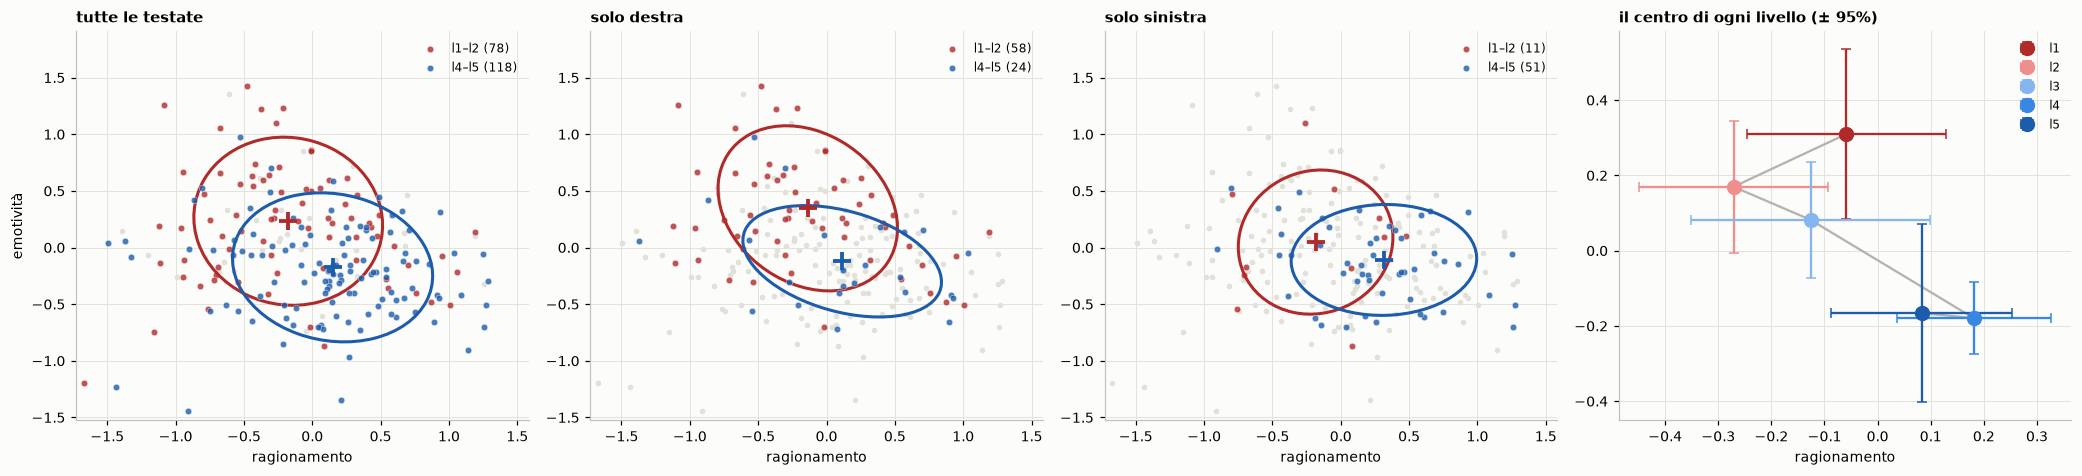

In [4]:
# 2.1 le testate sul piano: tutte, solo destra, solo sinistra, e il centro di ogni livello
gruppi = [("tutte le testate", np.ones(len(t), bool)), ("solo destra", (t.orientamento == "Right").to_numpy()),
          ("solo sinistra", (t.orientamento == "Left").to_numpy())]
fig, assi = plt.subplots(1, 4, figsize=(19, 4.4))
lim = {k: ind[k].quantile([0.01, 0.99]).to_numpy() + [-0.3, 0.3] for k in ind}
for ax, (nome, filtro) in zip(assi[:3], gruppi):
    b, a_ = basse & filtro, alte & filtro
    ax.scatter(ind.ragionamento[~(b | a_)], ind.emotività[~(b | a_)], s=7, color=FONDO)
    for m, colore, etichetta in [(b, ROSSO, "l1–l2"), (a_, BLU_SCURO, "l4–l5")]:
        ax.scatter(ind.ragionamento[m], ind.emotività[m], s=18, color=colore, alpha=0.8, edgecolor="white", linewidth=0.3, label=f"{etichetta} ({m.sum()})")
        ellisse(ax, ind.ragionamento[m], ind.emotività[m], colore)
    ax.set_xlim(*lim["ragionamento"]); ax.set_ylim(*lim["emotività"]); ax.set_xlabel("ragionamento"); ax.set_title(nome); ax.legend(fontsize=8)
assi[0].set_ylabel("emotività")
centri, errori = ind.groupby(lab).mean(), ind.groupby(lab).sem()
assi[3].plot(centri.ragionamento, centri.emotività, color=CHIARO, lw=1.5)
for k in range(5):
    assi[3].errorbar(centri.ragionamento[k], centri.emotività[k], xerr=1.96 * errori.ragionamento[k], yerr=1.96 * errori.emotività[k],
                     fmt="o", color=COLORE_LIVELLO[k], ms=9, capsize=3, label=F.LIVELLI[k])
assi[3].set_title("il centro di ogni livello (± 95%)"); assi[3].set_xlabel("ragionamento"); assi[3].legend(fontsize=8)
plt.tight_layout(); plt.savefig(GRAFICI / "stile_sul_piano.png", dpi=180, bbox_inches="tight"); plt.show()

## 3. Quanto separa ogni indice

In [5]:
# 3.1 AUC di ogni indice, l1–l2 contro l4–l5 (0,5 = a caso, 1 = separazione perfetta)
def auc(k, filtro):
    m = (basse | alte) & filtro
    a = roc_auc_score(alte[m], ind[k][m])
    return f"{max(a, 1 - a):.2f} ({'più alto' if a >= 0.5 else 'più basso'} nelle affidabili)"
pd.DataFrame({nome: {k: auc(k, filtro) for k in ind} for nome, filtro in gruppi})

,tutte le testate,solo destra,solo sinistra
ragionamento,0.66 (più alto nelle affidabili),0.63 (più alto nelle affidabili),0.73 (più alto nelle affidabili)
emotività,0.73 (più basso nelle affidabili),0.77 (più basso nelle affidabili),0.60 (più basso nelle affidabili)
